In [1]:
import sys
sys.path.append('../..')
import numpy as np
from algorithm.SymANLS_pivot import SymANLS_pivot
import matplotlib.pyplot as plt

In [24]:
import sys
sys.path.append('../..')
from algorithm.SymANLS_pivot import SymANLS_pivot
from data_preprocessing import coil20, cifar10, reuters, tdt2
import numpy as np
import matplotlib.pyplot as plt

CLUSTER_NUM = 5
r = CLUSTER_NUM # equal to the # of clusters
DATASET = tdt2
maxiter = 10000
lambda_ = 1

mat, truelabel = DATASET.read_data(num_of_class=CLUSTER_NUM, random_shuffle=True, 
                              random_choose_class=True)
# matrix processing
mat -= np.mean(mat)
norm = np.linalg.norm(mat, axis=1).reshape(-1, 1)
mat_normalized = mat / norm
X = mat_normalized @ mat_normalized.T

# initialization
U0 = np.random.rand(X.shape[0], r)
V0 = U0.copy()

U, V, e, t, diff, NMI, ACC = SymANLS_pivot(X, U0, V0, maxiter, lambda_, truelabel=truelabel, tol=1e-15)


iter 100 done, loss = 0.06256326874321119, error = 1.408963628502304e-06
last iter 137 Error: 0.0625632687396147


# algo1

In [25]:
import algorithm.algo1 as algo1
from importlib import reload

In [26]:
reload(algo1)
H = np.random.randn(X.shape[0], CLUSTER_NUM) + 1
# H.to(device)

# X_torch = torch.tensor(X, dtype=torch.float64)

H_out, P_out, t_algo1, e_algo1 = algo1.algo1_np_optimized(A=X, H=H, 
                           lamda=5, 
                           max_iter=10000000,
                           tol=1e-15, print_every=100)

M_NORM_SQUARE 4706.40714528671


iter 100 done, update = 0.0010759404199104788
iter 200 done, update = 0.004079698947613758


In [27]:
from algorithm import kmeans
import eval_metrics.ac, eval_metrics.nmi
reload(kmeans)
pred_labels, centroids = kmeans.kmeans_optimal(H_out, CLUSTER_NUM, turns=20)
acc = eval_metrics.ac.ac(truelabel, pred_labels)
nmi = eval_metrics.nmi.nmi(truelabel, pred_labels)
print(f'[Accuracy] {acc}\n[NMI] {nmi}')

[Accuracy] 0.9979508196721312
[NMI] 0.9928293260651027


In [28]:
len(t), len(t_algo1)

(138, 243)

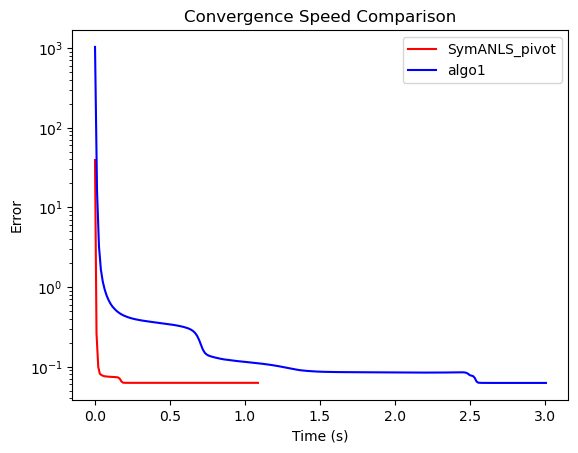

In [29]:
# y use log scale
plt.plot(t[:], e[:], c='r', label='SymANLS_pivot')
plt.plot(t_algo1[:], e_algo1[:], c='b', label='algo1')
plt.yscale('log')
plt.title('Convergence Speed Comparison')
plt.xlabel('Time (s)')
plt.ylabel('Error')
plt.legend()
plt.show()

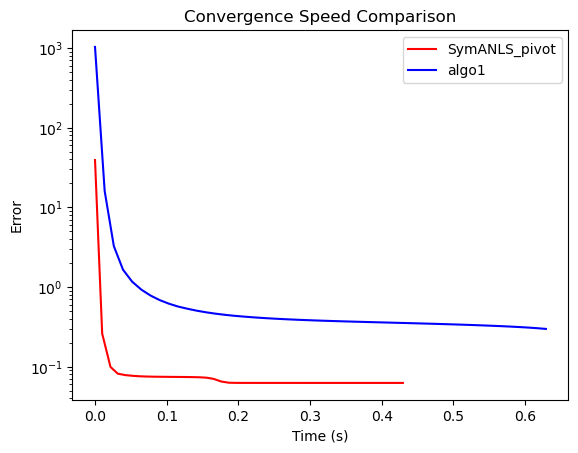

In [30]:
# y use log scale
length = 50
plt.plot(t[:length], e[:length], c='r', label='SymANLS_pivot')
plt.plot(t_algo1[:length], e_algo1[:length], c='b', label='algo1')
plt.yscale('log')
plt.title('Convergence Speed Comparison')
plt.xlabel('Time (s)')
plt.ylabel('Error')
plt.legend()
plt.show()

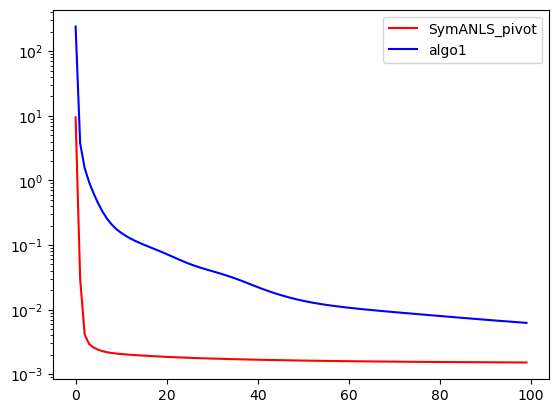

In [58]:
# y use log scale
plt.plot(range(100), e[:100], c='r', label='SymANLS_pivot')
plt.plot(range(100), e_algo1[:100], c='b', label='algo1')
plt.yscale('log')
plt.legend()
plt.show()